# Medium visual world — exploratory dataset analysis
Inspect the medium-world dataset used for staged/mixed/reverse comparisons. Scenes contain an `objects` list (3–5 objects), with colors/shapes, position, radius and angle. Questions include `EXISTS_COLOR`, `EXISTS_SHAPE`, `HAS_COLOR_AND_SHAPE` (independent conjunction), and `EXISTS_PAIR` (same-object binding).

**Important:** The same scene can support multiple question rows, so counting question rows as independent scenes can give misleading visual-frequency statistics. We deduplicate images/scenes for object distributions and keep question-weighted counts for query distributions. Default splits are `train`, `id_dev`, `ood_dev`; held-out test splits are excluded.

**Visualization update:** Section 1 now uses annotated object-count heatmaps instead of overlapping histograms. Re-run that cell to render the new figure; other saved tables are unaffected.


In [1]:
from pathlib import Path
from collections import Counter
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent
WORLD = 'medium'
INCLUDE_HELDOUT = False  # Avoid inspecting test distributions while developing the model.
CANDIDATES = [PROJECT_ROOT/'outputs/medium_world/dataset', PROJECT_ROOT/'medium_world/outputs/dataset']
DATA_DIR = next((p for p in CANDIDATES if (p / 'train.jsonl').exists()), None)
assert DATA_DIR is not None, f'No train.jsonl found. Check paths: {CANDIDATES}'
SPLITS = ['train', 'id_dev', 'ood_dev'] + (['adapt_train'] if WORLD=='small' else [])
if INCLUDE_HELDOUT: SPLITS += ['id_test', 'ood_test'] + (['adapt_test'] if WORLD=='small' else [])
rows = []
for split in SPLITS:
    path = DATA_DIR / f'{split}.jsonl'
    if path.exists():
        with path.open(encoding='utf-8') as file:
            for line in file:
                if line.strip():
                    obj = json.loads(line); obj['_loaded_split'] = split; rows.append(obj)
print('Dataset directory:', DATA_DIR, '| Question rows:', len(rows))
print('Splits:', Counter(r['_loaded_split'] for r in rows))

Dataset directory: c:\Users\Quoc Thai\Downloads\AI\AIO\Conquer\AIO Conquer 5 - visual_world\The-order-of-Learning\outputs\medium_world\dataset | Question rows: 11424
Splits: Counter({'train': 10000, 'id_dev': 1024, 'ood_dev': 400})


In [2]:
def objects_of(scene):
    if isinstance(scene, dict) and isinstance(scene.get('objects'), list):
        return scene['objects']
    if isinstance(scene, dict):
        return [v for v in scene.values() if isinstance(v, dict) and 'color' in v and 'shape' in v]
    raise ValueError(f'Unknown scene representation: {type(scene)}')

def references(question):
    # Capture queried color/shape *pairs* as well as individual attribute queries.
    # Nested REF nodes in small-world LEFT/ABOVE/XOR/CLOSER are handled recursively.
    found=[]
    if not isinstance(question,dict): return found
    op=str(question.get('op','')).upper(); args=question.get('args',[])
    if op in ('REF','EXISTS_PAIR','HAS_COLOR_AND_SHAPE') and len(args)>=2:
        if isinstance(args[0],str) and isinstance(args[1],str):
            found.append(('pair',str(args[0]),str(args[1])))
    elif op=='EXISTS_COLOR' and args and isinstance(args[0],str):
        found.append(('color',str(args[0]),''))
    elif op=='EXISTS_SHAPE' and args and isinstance(args[0],str):
        found.append(('shape',str(args[0]),''))
    for item in args:
        if isinstance(item,dict): found.extend(references(item))
        elif isinstance(item,list):
            for child in item:
                if isinstance(child,dict): found.extend(references(child))
    return found

def requested_attributes(refs):
    colors=set(); shapes=set(); pairs=set()
    for kind,c,s in refs:
        if kind in ('pair','color'): colors.add(c)
        if kind in ('pair','shape'): shapes.add(s if kind=='pair' else c)
        if kind=='pair': pairs.add((c,s))
    return colors,shapes,pairs

def scene_identity(row):
    if row.get('scene_id'): return str(row['scene_id'])
    canonical=json.dumps(row['scene'],sort_keys=True,separators=(',',':'))
    return hashlib.sha1(canonical.encode()).hexdigest()

qrows=[]; scene_records={}; targets=[]; object_records=[]
for row in rows:
    split=row['_loaded_split']; task=str(row.get('template','unknown'))
    scene=row['scene']; obs=objects_of(scene); scene_id=scene_identity(row)
    ocolors=Counter(o['color'] for o in obs); oshapes=Counter(o['shape'] for o in obs)
    opairs=Counter((o['color'],o['shape']) for o in obs)
    refs=references(row.get('question',{})); qc, qs, qp=requested_attributes(refs)
    unique_qc=sorted(qc); unique_qs=sorted(qs); unique_qp=sorted(qp)
    label=int(row['label'])
    key=(split,scene_id)
    if key not in scene_records:
        scene_records[key]={'split':split,'scene_id':scene_id,'n_objects':len(obs),
            'n_unique_colors':len(ocolors),'n_unique_shapes':len(oshapes),
            'repeated_color':int(max(ocolors.values(),default=0)>1),
            'repeated_shape':int(max(oshapes.values(),default=0)>1),
            'n_unique_pairs':len(opairs)}
        for obj in obs:
            object_records.append({'split':split,'scene_id':scene_id, 'color':obj['color'],
                 'shape':obj['shape'],'size':obj.get('size'),
                 'radius':obj.get('radius'),'angle':obj.get('angle')})
    qid=str(row.get('id',f'{split}_{len(qrows)}'))
    qrows.append({'split':split,'scene_id':scene_id,'id':qid,'template':task,
        'op':row.get('question',{}).get('op',''), 'label':label,
        'level':row.get('level'), 'n_objects':len(obs),
        'n_unique_colors':len(ocolors), 'n_unique_shapes':len(oshapes),
        'n_queried_colors':len(qc), 'n_queried_shapes':len(qs), 'n_queried_pairs':len(qp),
        'all_colors_present':all(ocolors[c]>0 for c in qc) if qc else np.nan,
        'all_shapes_present':all(oshapes[s]>0 for s in qs) if qs else np.nan,
        'all_pairs_present':all(opairs[p]>0 for p in qp) if qp else np.nan,
        'any_pairs_present':any(opairs[p]>0 for p in qp) if qp else np.nan,
        'all_reference_pairs_present':all(opairs[p]>0 for p in qp) if qp else np.nan,
        'queried_color':unique_qc[0] if len(qc)==1 else None,
        'queried_shape':unique_qs[0] if len(qs)==1 else None,
        'queried_pair':f'{unique_qp[0][0]} + {unique_qp[0][1]}' if len(qp)==1 else None,
        'heldout_pair':str(row.get('heldout_pair')) if row.get('heldout_pair') else None,
        'closer_margin':row.get('closer_margin'),
        'p_q':str(row.get('p_q')) if row.get('p_q') is not None else None})
    # For target queries, count each requested attribute once per question (not repeated REF occurrences).
    for c in unique_qc:
        targets.append({'split':split,'template':task,'id':qid,'label':label,
                        'kind':'color','target':c,'present':int(ocolors[c]>0),'matches':ocolors[c]})
    for s in unique_qs:
        targets.append({'split':split,'template':task,'id':qid,'label':label,
                        'kind':'shape','target':s,'present':int(oshapes[s]>0),'matches':oshapes[s]})
    for c,s in unique_qp:
        targets.append({'split':split,'template':task,'id':qid,'label':label,
                        'kind':'pair','target':f'{c} + {s}',
                        'present':int(opairs[(c,s)]>0),'matches':opairs[(c,s)]})

questions=pd.DataFrame(qrows);scenes=pd.DataFrame(list(scene_records.values()))
objs=pd.DataFrame(object_records); target_df=pd.DataFrame(targets)
assert len(questions)==len(rows)
assert not scenes.duplicated(['split','scene_id']).any()
print('Questions:',len(questions),'| Unique split/scene records:',len(scenes),
      '| Objects in unique scenes:',len(objs),'| Requested target rows:',len(target_df))

Questions: 11424 | Unique split/scene records: 5912 | Objects in unique scenes: 23626 | Requested target rows: 23248


## 1. Dataset inventory and label balance
**Questions:** How many scenes, question examples, and objects are there? Are classes balanced within every task? Are any scenes reused across questions? We report both scene-unique and question-weighted counts to avoid double counting.

In [3]:
summary=questions.groupby(['split','template']).agg(
    questions=('id','size'),yes_rate=('label','mean'),unique_scenes=('scene_id','nunique'),
    avg_objects=('n_objects','mean')).reset_index()
summary['yes_rate']*=100
print('Counts by split and task (yes_rate in %):');display(summary.round(2))
scene_summary=scenes.groupby('split').agg(unique_scenes=('scene_id','nunique'),
    mean_objects=('n_objects','mean'),mean_unique_colors=('n_unique_colors','mean'),
    mean_unique_shapes=('n_unique_shapes','mean')).round(2)
print('Scene-weighted statistics:');display(scene_summary)
print('Questions per scene (within split):')
display(questions.groupby(['split','scene_id']).size().groupby('split').value_counts().rename('number_of_scenes').to_frame())
print('Scene-ID overlap across splits:')
for i,a in enumerate(questions.split.unique()):
    for b in questions.split.unique()[i+1:]:
        overlap=len(set(scenes.loc[scenes.split==a,'scene_id']) & set(scenes.loc[scenes.split==b,'scene_id']))
        print(f'  {a} vs {b}: {overlap}')

Counts by split and task (yes_rate in %):


,split,template,questions,yes_rate,unique_scenes,avg_objects
0,id_dev,color,256,50.0,256,4.05
1,id_dev,conjunction,256,50.0,256,3.93
2,id_dev,pair,256,50.0,256,4.05
3,id_dev,shape,256,50.0,256,3.93
4,ood_dev,pair,400,50.0,400,4.19
5,train,color,2500,50.0,2500,3.97
6,train,conjunction,2500,50.0,2500,3.99
7,train,pair,2500,50.0,2500,4.01
8,train,shape,2500,50.0,2500,3.95


Scene-weighted statistics:


,unique_scenes,mean_objects,mean_unique_colors,mean_unique_shapes
split,,,,
id_dev,512,3.99,2.88,2.67
ood_dev,400,4.19,3.06,2.87
train,5000,3.98,2.89,2.67


Questions per scene (within split):


,,number_of_scenes
split,,
id_dev,2,512
ood_dev,1,400
train,2,5000


Scene-ID overlap across splits:
  train vs id_dev: 0
  train vs ood_dev: 0
  id_dev vs ood_dev: 0


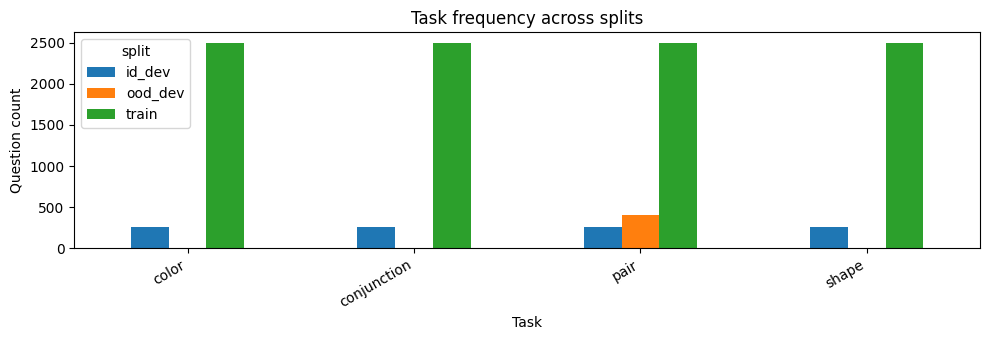

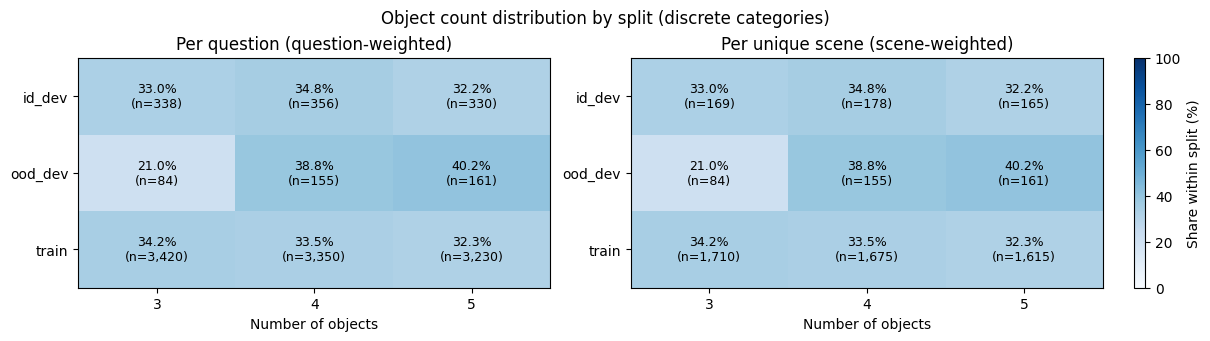

In [4]:
fig,ax=plt.subplots(figsize=(10,3.5))
tab=pd.crosstab(questions['template'],questions['split']).sort_index()
tab.plot(kind='bar',ax=ax);ax.set_ylabel('Question count');ax.set_xlabel('Task')
ax.set_title('Task frequency across splits');plt.xticks(rotation=30,ha='right');plt.tight_layout();plt.show()

# Clear, non-overlapping display: annotated heatmaps of discrete object counts.
# Question-weighted and unique-scene-weighted distributions can differ when scenes are reused.
fig, ax = plt.subplots(1, 2, figsize=(12, max(3.3, 0.55*questions.split.nunique()+1.5)), constrained_layout=True)
for a, (df, title) in zip(ax, [
    (questions, 'Per question (question-weighted)'),
    (scenes, 'Per unique scene (scene-weighted)')
]):
    counts = pd.crosstab(df['split'], df['n_objects']).sort_index()
    counts = counts.reindex(columns=sorted(set(questions.n_objects) | set(scenes.n_objects)), fill_value=0)
    percentages = counts.div(counts.sum(axis=1), axis=0).mul(100)
    im = a.imshow(percentages.to_numpy(), aspect='auto', vmin=0, vmax=100, cmap='Blues')
    a.set_xticks(range(len(counts.columns)), [str(x) for x in counts.columns])
    a.set_yticks(range(len(counts.index)), counts.index)
    a.set_xlabel('Number of objects'); a.set_title(title)
    for row in range(len(counts.index)):
        for col in range(len(counts.columns)):
            value = percentages.iat[row, col]
            a.text(col, row, f'{value:.1f}%\n(n={counts.iat[row,col]:,})',
                   ha='center', va='center', fontsize=9,
                   color='white' if value >= 55 else 'black')
fig.suptitle('Object count distribution by split (discrete categories)', fontsize=12)
fig.colorbar(im, ax=ax, label='Share within split (%)', fraction=.035, pad=.03)
plt.show()


## 2. Which colors and shapes actually appear?
**Questions:** What colors/shapes are most common in the image? Which combinations occur? Is an attribute present in many scenes because it repeats within scenes? Object counts below are **deduplicated by scene**. The second table reports the probability a unique scene contains an attribute.


COLOR: object occurrence counts


split,id_dev,ood_dev,train
color,,,
blue,372,317,3738
green,403,352,3739
purple,410,351,3719
red,350,329,3700
yellow,509,328,5009


COLOR: % of unique scenes containing it


color,blue,green,purple,red,yellow
split,,,,,
id_dev,54.1,58.0,58.8,50.0,67.0
ood_dev,58.2,63.0,65.0,61.0,59.0
train,55.3,56.1,55.3,54.8,67.8


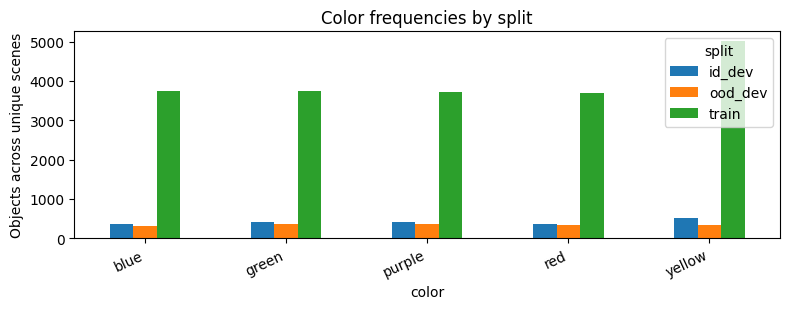


SHAPE: object occurrence counts


split,id_dev,ood_dev,train
shape,,,
circle,484,435,5136
crescent,549,410,4878
square,513,406,4919
triangle,498,426,4972


SHAPE: % of unique scenes containing it


shape,circle,crescent,square,triangle
split,,,,
id_dev,64.6,69.7,67.8,65.0
ood_dev,73.5,70.0,70.8,72.5
train,68.3,65.9,66.2,66.7


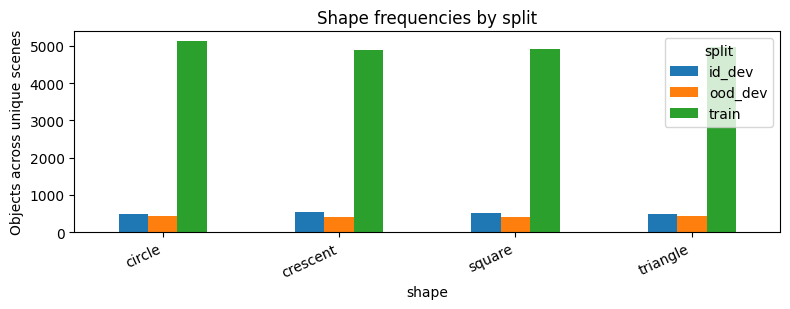

Object-level color × shape counts (train scenes):


shape,circle,crescent,square,triangle
color,,,,
blue,1252,1248,0,1238
green,0,1216,1261,1262
purple,1309,1201,1209,0
red,1256,0,1210,1234
yellow,1319,1213,1239,1238


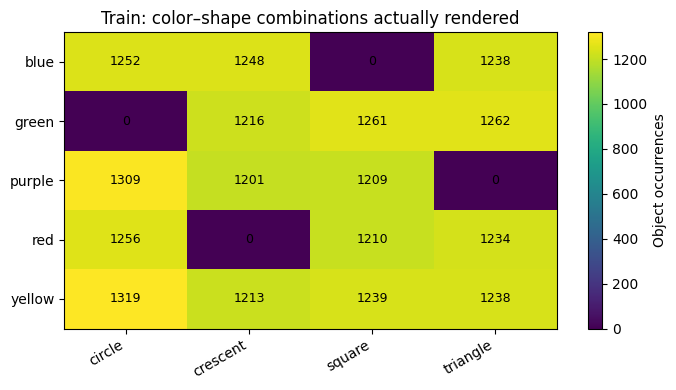

In [5]:
for attribute in ['color','shape']:
    counts=pd.crosstab(objs[attribute],objs['split'])
    pres=(objs.drop_duplicates(['split','scene_id',attribute])
           .groupby(['split',attribute]).size().unstack(fill_value=0))
    pres=pres.div(scenes.groupby('split').size(),axis=0).mul(100)
    print(f'\n{attribute.upper()}: object occurrence counts');display(counts)
    print(f'{attribute.upper()}: % of unique scenes containing it');display(pres.round(1))
    fig,ax=plt.subplots(figsize=(8,3.2))
    counts.plot(kind='bar',ax=ax)
    ax.set_ylabel('Objects across unique scenes');ax.set_title(f'{attribute.title()} frequencies by split')
    plt.xticks(rotation=25,ha='right');plt.tight_layout();plt.show()
print('Object-level color × shape counts (train scenes):')
cooccur=pd.crosstab(objs.loc[objs.split=='train','color'],objs.loc[objs.split=='train','shape'])
display(cooccur)
fig,ax=plt.subplots(figsize=(7,4))
im=ax.imshow(cooccur.values,aspect='auto')
ax.set_xticks(range(len(cooccur.columns)),cooccur.columns,rotation=30,ha='right')
ax.set_yticks(range(len(cooccur.index)),cooccur.index)
ax.set_title('Train: color–shape combinations actually rendered')
for i in range(cooccur.shape[0]):
    for j in range(cooccur.shape[1]):ax.text(j,i,str(cooccur.iloc[i,j]),ha='center',va='center',fontsize=9)
plt.colorbar(im,ax=ax,label='Object occurrences');plt.tight_layout();plt.show()

## 3. What attributes are being asked?
**Questions:** Do question generators favor particular colors, shapes or pairs? Does the distribution change by task or split? Nested small-world questions may request multiple distinct attributes, so totals can exceed the number of questions. Repeated references to the same attribute within one question are counted once.


Requested color targets by task (train):


template,color,conjunction,pair
target,,,
blue,498,467,473
green,500,466,470
purple,500,469,468
red,502,472,468
yellow,500,626,621


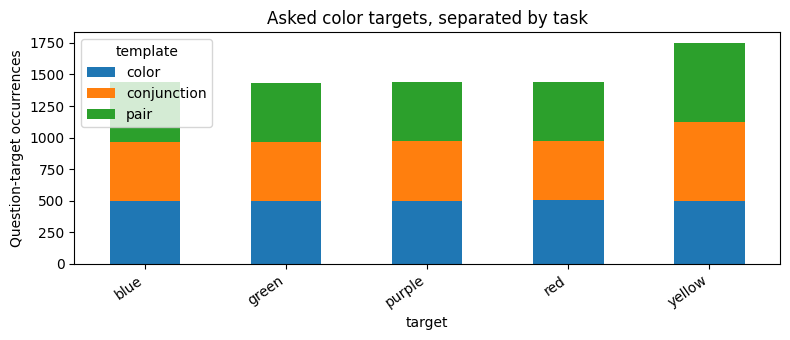


Requested shape targets by task (train):


template,conjunction,pair,shape
target,,,
circle,626,624,626
crescent,623,628,623
square,625,621,625
triangle,626,627,626


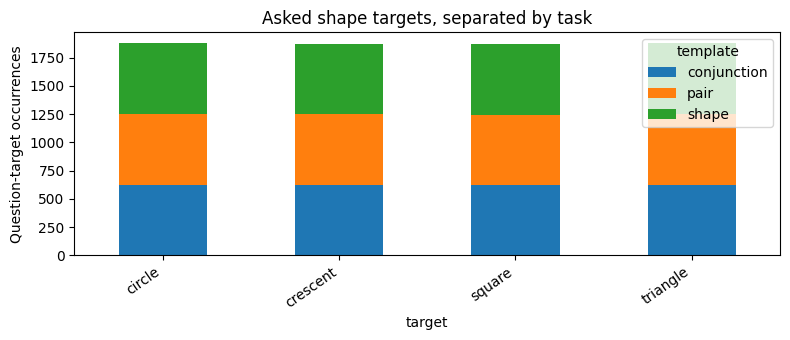


Requested pair targets by task (train):


template,conjunction,pair
target,,
blue + circle,156,156
blue + crescent,155,158
blue + triangle,156,159
green + crescent,156,158
green + square,154,156
green + triangle,156,156
purple + circle,156,156
purple + crescent,156,156
purple + square,157,156


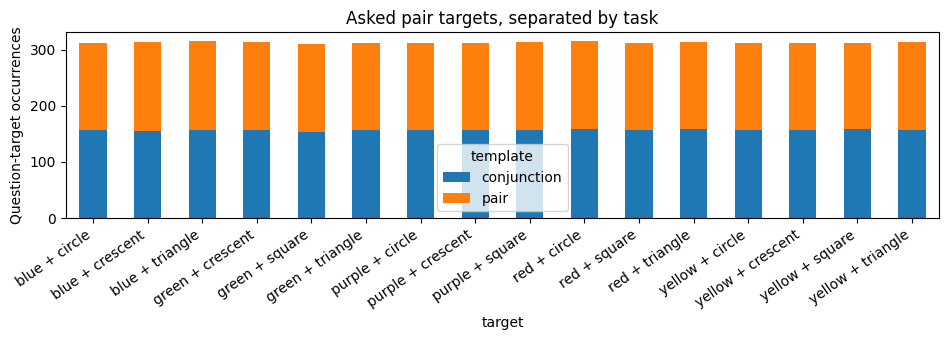

Number of DISTINCT queried attributes per question:


n_queried_colors  n_queried_shapes  n_queried_pairs
split   template                                                        
id_dev  color                     1.0               0.0              0.0
        conjunction               1.0               1.0              1.0
        pair                      1.0               1.0              1.0
        shape                     0.0               1.0              0.0
ood_dev pair                      1.0               1.0              1.0
train   color                     1.0               0.0              0.0
        conjunction               1.0               1.0              1.0
        pair                      1.0               1.0              1.0
        shape                     0.0               1.0              0.0

In [6]:
for kind in ['color','shape','pair']:
    part=target_df[(target_df.kind==kind) & (target_df.split=='train')]
    if part.empty:continue
    frequency=pd.crosstab(part['target'],part['template'])
    print(f'\nRequested {kind} targets by task (train):');display(frequency)
    fig,ax=plt.subplots(figsize=(max(8,0.6*len(frequency)),3.5))
    frequency.plot(kind='bar',stacked=True,ax=ax)
    ax.set_ylabel('Question-target occurrences');ax.set_title(f'Asked {kind} targets, separated by task')
    plt.xticks(rotation=35,ha='right');plt.tight_layout();plt.show()
print('Number of DISTINCT queried attributes per question:')
display(questions.groupby(['split','template'])[['n_queried_colors','n_queried_shapes','n_queried_pairs']].mean().round(2))

## 4. Does an asked attribute actually appear in the scene?
**Questions:** Given that a question asks about *red*, how often is there red in the image? What changes for negative vs positive labels, and for different tasks? These are conditional rates over **question-target pairs**, not unconditional prevalence. For `LEFT`/`XOR`/`CLOSER`, presence alone is insufficient to determine the answer.

Presence of asked attributes, separated by split, task and label:


,split,template,kind,label,n,present_pct,avg_matches
0,id_dev,color,color,0,128,0.00,0.00
1,id_dev,color,color,1,128,100.00,1.41
2,id_dev,conjunction,color,0,128,40.62,0.51
3,id_dev,conjunction,color,1,128,100.00,1.57
4,id_dev,conjunction,pair,0,128,0.00,0.00
5,id_dev,conjunction,pair,1,128,60.16,0.74
6,id_dev,conjunction,shape,0,128,59.38,0.85
7,id_dev,conjunction,shape,1,128,100.00,1.65
8,id_dev,pair,color,0,128,100.00,1.18
9,id_dev,pair,color,1,128,100.00,1.60



P(requested color present | task, label), train:


label,0,1
template,,
color,0.0,100.0
conjunction,42.7,100.0
pair,100.0,100.0


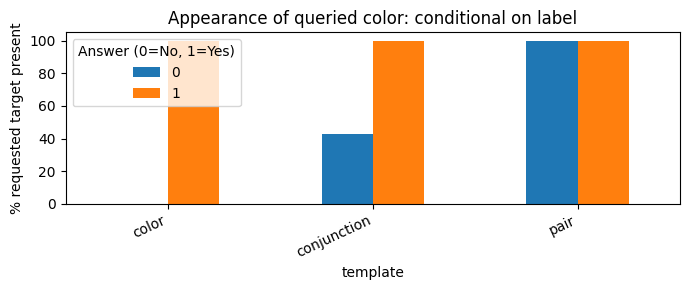


P(requested shape present | task, label), train:


label,0,1
template,,
conjunction,57.3,100.0
pair,100.0,100.0
shape,0.0,100.0


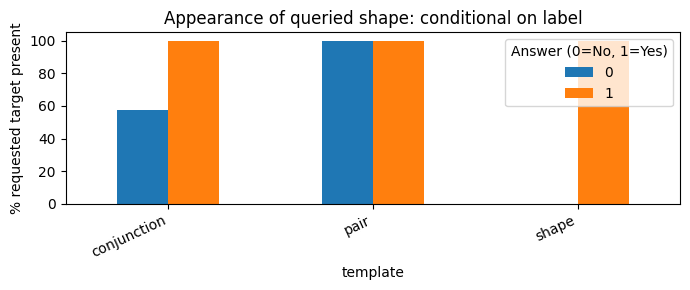


P(requested pair present | task, label), train:


label,0,1
template,,
conjunction,0.0,60.7
pair,0.0,100.0


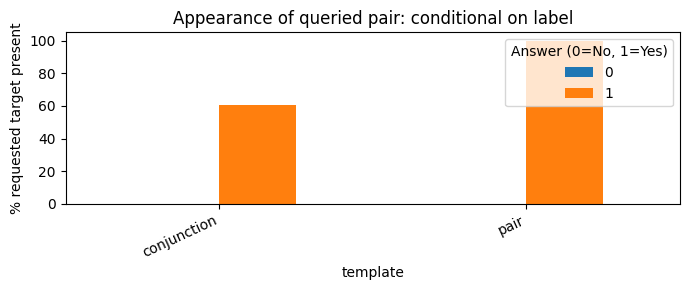

In [7]:
presence=(target_df.groupby(['split','template','kind','label'])
          .agg(n=('present','size'),present_pct=('present',lambda x:100*x.mean()),
               avg_matches=('matches','mean')).reset_index())
print('Presence of asked attributes, separated by split, task and label:')
display(presence.round(2))
for kind in ['color','shape','pair']:
    part=target_df[(target_df.split=='train')&(target_df.kind==kind)]
    if part.empty: continue
    h=part.groupby(['template','label'])['present'].mean().unstack()
    print(f'\nP(requested {kind} present | task, label), train:')
    display((100*h).round(1))
    fig,ax=plt.subplots(figsize=(max(7,len(h)*1.2),3))
    h.mul(100).plot(kind='bar',ax=ax)
    ax.set_ylabel('% requested target present');ax.set_ylim(0,105)
    ax.set_title(f'Appearance of queried {kind}: conditional on label')
    ax.legend(title='Answer (0=No, 1=Yes)');plt.xticks(rotation=25,ha='right');plt.tight_layout();plt.show()

## 5. Can the answer be guessed from the question alone?
**Questions:** Does asking about blue, a square, or a particular pair make `Yes` more likely? The table below shows per-target `Yes` rates and deviation from the task's overall `Yes` rate. An attribute can occur in multiple question targets; this is exploratory, not a trained classifier.

In [8]:
qbase=questions.groupby(['split','template'])['label'].mean().rename('task_yes_rate')
leak=(target_df.groupby(['split','template','kind','target'])['label']
      .agg(n='size',yes_rate='mean').reset_index()
      .merge(qbase.reset_index(),on=['split','template'],how='left'))
leak['shift_percentage_points']=100*(leak['yes_rate']-leak['task_yes_rate'])
subset=leak[(leak.split=='train')&(leak.n>=10)].copy()
if len(subset):
    ranked=subset.reindex(subset.shift_percentage_points.abs().sort_values(ascending=False).index)
    print('Top question-target/label associations (train, minimum 10 questions):')
    display(ranked.head(25).round(2))
else: print('Too few repeated targets for the n>=10 display threshold.')
print('Task baseline Yes rates:')
display((100*qbase).round(1).rename('yes_rate_pct').to_frame())

Top question-target/label associations (train, minimum 10 questions):

,split,template,kind,target,n,yes_rate,task_yes_rate,shift_percentage_points
120,train,pair,pair,yellow + square,153,0.5,0.5,0.33
118,train,pair,pair,yellow + circle,155,0.5,0.5,-0.32
82,train,conjunction,pair,blue + crescent,155,0.5,0.5,0.32
117,train,pair,pair,red + triangle,155,0.5,0.5,0.32
115,train,pair,pair,red + circle,157,0.5,0.5,0.32
89,train,conjunction,pair,purple + square,157,0.5,0.5,-0.32
121,train,pair,pair,yellow + triangle,157,0.5,0.5,-0.32
108,train,pair,pair,blue + triangle,159,0.5,0.5,-0.31
104,train,pair,color,red,468,0.5,0.5,0.21
76,train,conjunction,color,blue,467,0.5,0.5,0.11


Task baseline Yes rates:


yes_rate_pct
split   template                 
id_dev  color                50.0
        conjunction          50.0
        pair                 50.0
        shape                50.0
ood_dev pair                 50.0
train   color                50.0
        conjunction          50.0
        pair                 50.0
        shape                50.0

## 6. Task-specific logical shortcuts (color, shape, conjunction, pair)
For a simple `conjunction`, a positive answer needs **both** attributes somewhere; `pair` needs them on the **same object**. `color-only` and `shape-only` rules are shortcuts, not model predictions. For other relational tasks, the table is not applicable.

In [9]:
simple_ops={'EXISTS_COLOR','EXISTS_SHAPE','EXISTS_PAIR','HAS_COLOR_AND_SHAPE'}
simple=questions[questions.op.isin(simple_ops)].copy()
if len(simple):
    def logical_answer(r):
        if r.op=='EXISTS_COLOR': return int(bool(r.all_colors_present))
        if r.op=='EXISTS_SHAPE': return int(bool(r.all_shapes_present))
        if r.op=='HAS_COLOR_AND_SHAPE':return int(bool(r.all_colors_present) and bool(r.all_shapes_present))
        if r.op=='EXISTS_PAIR':return int(bool(r.all_pairs_present))
        return np.nan
    simple['oracle_from_scene']=simple.apply(logical_answer,axis=1)
    mismatch=simple[simple.oracle_from_scene != simple.label]
    print('Scene-derived oracle mismatch:',len(mismatch),'/',len(simple))
    if len(mismatch):display(mismatch[['split','template','id','label','oracle_from_scene']].head())
    for op in ['HAS_COLOR_AND_SHAPE','EXISTS_PAIR']:
        ss=simple[simple.op==op].copy()
        if ss.empty:continue
        ss['color_only']=ss.all_colors_present.astype(int)
        ss['shape_only']=ss.all_shapes_present.astype(int)
        ss['both_attrs_present']=(ss.all_colors_present & ss.all_shapes_present).astype(int)
        ss['pair_present']=ss.any_pairs_present.astype(int)
        print(f'\n{op}: shortcut accuracy and hard-negative frequency by split:')
        table=ss.groupby('split').apply(lambda x:pd.Series({
            'questions':len(x),'color_only_acc':(x.color_only==x.label).mean(),
            'shape_only_acc':(x.shape_only==x.label).mean(),
            'both_present_acc':(x.both_attrs_present==x.label).mean(),
            'negative_both_attrs_pct':100*((x.label==0)&(x.both_attrs_present==1)).sum()/max((x.label==0).sum(),1),
            'negative_pair_absent_pct':100*((x.label==0)&(x.pair_present==0)).sum()/max((x.label==0).sum(),1)
        }),include_groups=False)
        display(table.round(3))
else:
    print('No simple existence-type questions in loaded splits.')

Scene-derived oracle mismatch: 0 / 11424

HAS_COLOR_AND_SHAPE: shortcut accuracy and hard-negative frequency by split:


,questions,color_only_acc,shape_only_acc,both_present_acc,negative_both_attrs_pct,negative_pair_absent_pct
split,,,,,,
id_dev,256.0,0.797,0.703,1.0,0.0,100.0
train,2500.0,0.786,0.714,1.0,0.0,100.0



EXISTS_PAIR: shortcut accuracy and hard-negative frequency by split:


,questions,color_only_acc,shape_only_acc,both_present_acc,negative_both_attrs_pct,negative_pair_absent_pct
split,,,,,,
id_dev,256.0,0.5,0.5,0.5,100.0,100.0
ood_dev,400.0,0.5,0.5,0.5,100.0,100.0
train,2500.0,0.5,0.5,0.5,100.0,100.0


## 7. What makes the scene harder?
Report object count, repeated colors, and repeated shapes by task and label. These factors may affect visual ambiguity even when labels are balanced. Medium-world size/angle/radius are available at object level; small-world has a small/large size categorical attribute.

In [10]:
print('Scene structural difficulty (unique scenes):')
display(scenes.groupby('split')[['n_objects','n_unique_colors','n_unique_shapes','repeated_color','repeated_shape']].agg(['mean','std']).round(2))
print('Object count by task and label (question weighted):')
display(questions.groupby(['split','template','label'])['n_objects'].agg(['count','mean','std']).round(2))
for field in ['size','radius','angle']:
    if objs[field].notna().any():
        print(f'\nObject {field} distribution by split:')
        display(pd.crosstab(objs[field],objs.split))

Scene structural difficulty (unique scenes):


n_objects       n_unique_colors       n_unique_shapes        \
             mean   std            mean   std            mean   std   
split                                                                 
id_dev       3.99  0.81            2.88  0.77            2.67  0.68   
ood_dev      4.19  0.76            3.06  0.67            2.87  0.66   
train        3.98  0.82            2.89  0.73            2.67  0.65   

        repeated_color       repeated_shape        
                  mean   std           mean   std  
split                                              
id_dev            0.80  0.40           0.85  0.35  
ood_dev           0.78  0.42           0.86  0.35  
train             0.77  0.42           0.84  0.36

Object count by task and label (question weighted):


count  mean   std
split   template    label                   
id_dev  color       0        128  4.03  0.81
                    1        128  4.08  0.80
        conjunction 0        128  3.93  0.82
                    1        128  3.93  0.81
        pair        0        128  4.05  0.84
                    1        128  4.05  0.82
        shape       0        128  3.91  0.81
                    1        128  3.95  0.77
ood_dev pair        0        200  4.18  0.76
                    1        200  4.21  0.76
train   color       0       1250  3.95  0.82
                    1       1250  4.00  0.81
        conjunction 0       1250  3.98  0.81
                    1       1250  4.00  0.81
        pair        0       1250  4.04  0.82
                    1       1250  3.98  0.80
        shape       0       1250  3.88  0.82
                    1       1250  4.02  0.82


Object radius distribution by split:


split,id_dev,ood_dev,train
radius,,,
5,509,446,4996
6,517,393,5043
7,539,435,4934
8,479,403,4932



Object angle distribution by split:


split,id_dev,ood_dev,train
angle,,,
0,898,732,8868
45,369,317,3646
90,128,103,1223
135,113,105,1252
180,159,96,1251
225,115,97,1254
270,141,122,1228
315,121,105,1183


## 8. OOD and held-out combination audit
Compare appearance of queried color–shape combinations across splits. These tables can reveal whether OOD development actually asks about unseen combinations and whether those combinations appear as objects in the train scenes. This is an audit of the **dataset**, not an evaluation of a model.

In [11]:
print('Pair combinations requested, by task and split:')
pp=target_df[target_df.kind=='pair']
if len(pp):
    display(pd.crosstab([pp.template,pp.target],pp.split))
    display(pp.groupby(['split','template'])['present'].agg(['size','mean']).round(3))
print('Pairs actually present as objects in unique scenes, by split:')
comb=objs.assign(pair=objs.color+' + '+objs['shape'])
display(pd.crosstab(comb.pair,comb.split))
metadata_path=DATA_DIR/'dataset_metadata.json'
if metadata_path.exists():
    metadata=json.loads(metadata_path.read_text(encoding='utf-8'))
    heldout=metadata.get('heldout_pairs',metadata.get('config',{}).get('holdout'))
    print('Held-out pairs declared by dataset metadata:',heldout)
    if heldout:
        for c,s in heldout:
            k=f'{c} + {s}'
            seen=comb[comb.pair==k].groupby('split').size().to_dict()
            asked=pp[pp.target==k].groupby('split').size().to_dict()
            print(f'{k}: rendered object occurrences={seen}, question targets={asked}')
if questions.heldout_pair.notna().any():
    print('Record-level heldout_pair tags:')
    display(pd.crosstab(questions.heldout_pair,questions.split))

Pair combinations requested, by task and split:


split                          id_dev  ood_dev  train
template    target                                   
conjunction blue + circle          16        0    156
            blue + crescent        16        0    155
            blue + triangle        16        0    156
            green + crescent       16        0    156
            green + square         16        0    154
            green + triangle       16        0    156
            purple + circle        16        0    156
            purple + crescent      16        0    156
            purple + square        17        0    157
            red + circle           16        0    158
            red + square           15        0    156
            red + triangle         16        0    158
            yellow + circle        16        0    156
            yellow + crescent      16        0    156
            yellow + square        16        0    158
            yellow + triangle      16        0    156
pair        blue + circle          14        0    156
            blue + crescent        16        0    158
            blue + square           0       97      0
            blue + triangle        18        0    159
            green + circle          0      109      0
            green + crescent       18        0    158
            green + square         14        0    156
            green + triangle       16        0    156
            purple + circle        18        0    156
            purple + crescent      16        0    156
            purple + square        15        0    156
            purple + triangle       0      111      0
            red + circle           16        0    157
            red + crescent          0       83      0
            red + square           16        0    156
            red + triangle         14        0    155
            yellow + circle        18        0    155
            yellow + crescent      16        0    156
            yellow + square        15        0    153
            yellow + triangle      16        0    157

size   mean
split   template                
id_dev  conjunction   256  0.301
        pair          256  0.500
ood_dev pair          400  0.500
train   conjunction  2500  0.304
        pair         2500  0.500

Pairs actually present as objects in unique scenes, by split:


split,id_dev,ood_dev,train
pair,,,
blue + circle,126,84,1252
blue + crescent,127,91,1248
blue + square,0,65,0
blue + triangle,119,77,1238
green + circle,0,77,0
green + crescent,153,90,1216
green + square,108,79,1261
green + triangle,142,106,1262
purple + circle,131,93,1309


Held-out pairs declared by dataset metadata: [['blue', 'square'], ['green', 'circle'], ['purple', 'triangle'], ['red', 'crescent']]
blue + square: rendered object occurrences={'ood_dev': 65}, question targets={'ood_dev': 97}
green + circle: rendered object occurrences={'ood_dev': 77}, question targets={'ood_dev': 109}
purple + triangle: rendered object occurrences={'ood_dev': 76}, question targets={'ood_dev': 111}
red + crescent: rendered object occurrences={'ood_dev': 54}, question targets={'ood_dev': 83}
